# Comparative Reliability Performance of N-Body Simulation under Hamiltonian Framework Applying Barnes-Hut Trees
Within the realms of modern orbital mechanics application of Barnes-Hut trees is a common practice for large N-Body simulations (Barnes & Hut, 1986). The project describes the creation of a C++ and R tool to simulate the problem assessing reliability of the Barnes-Hut trees for cosmological applications via application of symplectic and non-symplectic integration schemes.

## About The Notebook
This notebook is a simulation prototype, that shows fast results and validation of said results using Python.
It will be kept in a dated entry order expanding each individual feature for a later transfer to C++ and R framework.
It will also comply with the project's gantt chart of progress.

Please bear in mind that the function and variable names follow a certain pattern:
- Integrators and their daughter functions: `operation_integrator_order`
- Mathematical equations take their literal mathematical names, where numerator is a numerator, product is a product, etc.

Displayed equations are numbered consecutively through the whole notebook and are cited as Eq. (*n*). Sources are cited in the Author (Year) form and are listed in the References section at the end of the notebook.

## Setting the Environment and Creating Velocity Verlet 4th Order

In [1]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import random as rnd
import time

# Randomisation Seed
seed = 256
rnd.seed(seed)

# Constants
yoshida_x0 = -(2**(1/3))/(2-(2**(1/3)))
yoshida_x1 = (1/(2-(2**(1/3))))

In [2]:
"""
Creating helper functions to help with force evaluation later.
"""

# Find Euclidian distance between two bodies
# obj_a – object i with accessible properties
# obj_b - object j with accessible properties
def euclidian_distance(obj_a, obj_b):
    return np.linalg.norm(obj_a.r - obj_b.r)

# Find initial velocity
# obj – individual object with accessible properties
# G – constant of gravitational attraction
# distance – previously found Euclidian distance
def vel_init(obj, G, distance):
    return rnd.random() * np.sqrt((G*obj.m) / distance)  # random variable in the beginning is used to create random orbit eccentricities (no ejection)

# Get a perpendicular vector
def get_perpendicular(v):
    x, y, z = v
    if x != 0 or y != 0:
        perp = np.array([-y, x, 0.0], dtype=float)
    else:
        perp = np.array([0.0, 1.0, 0.0], dtype=float)

    return perp

# Find velocity direction
# Essentially convert scalar velocity into vector velocity
# obj_a – object i with accessible properties
# obj_b - object j with accessible properties
# v – scalar velocity
def vel_direction(obj_a, obj_b, v):
    radius_vector = obj_b.r - obj_a.r
    perp_vector = get_perpendicular(radius_vector)
    unit_perp_vector = perp_vector / np.linalg.norm(perp_vector)    # normalise by its own length

    return v * unit_perp_vector


# Compute Gravitational Acceleration of All Bodies acting on i
# G – the constant of gravitational attraction
# bod_obj – a list of stellar bodies represented as objects.
#           Contains objects themselves. Allows to access
#           individual parameters such as: mass, initial velocity,
#           and initial displacement.
# e – softening factor to prevent division by 0 errors in case
#     the bodies get too close.
def acc(G, bod_obj, e):
    N = len(bod_obj)    
    accelerations = [np.zeros(3) for _ in range(N)]     # initialise an array to hold acceleration vectors for all bodies

    # Sigma operation
    # Loop over every body i
    for i in range(N):
        a_i = np.zeros(3)   # net acceleration vector on body i

        # Sum gravitational pull from every other body j
        for j in range(N):
            if i == j:
                continue    # idiot-proofing self-interaction

            # Compute displacement from i to j
            r_ij = bod_obj[i].r - bod_obj[j].r

            # Scalar distance squared
            dist_sq = np.sum(r_ij**2)

            # Denominator with softening factor
            denominator = (dist_sq + e**2)**1.5

            # Add the j-body contribution
            a_i += bod_obj[j].m * (r_ij / denominator)

        # Apply -G and store the net acceleration for body i
        accelerations[i] = -G * a_i

    return accelerations


In [3]:
"""
Conservation Value Calculations

This cell contains all the functions to help with the conservation and will be further embedded into the code.
Here, we will define later-mentioned Hamiltonian and momenta conservations, as well as their relative values.
"""

# Calculate the kinetic energy of the system: T = sum_i |p_i|^2 / (2 m_i)
# bod_obj – a list of stellar bodies represented as objects.
#           Contains objects themselves. Allows to access
#           individual parameters such as: mass, initial velocity,
#           and initial displacement.
def t_abs(bod_obj):
    t = 0.0     # total kinetic energy
    # Iterate through the list of bodies to extract individual values for the velocity and mass
    for obj in bod_obj:
        p = obj.m * obj.v       # linear momentum vector of the body
        t += np.dot(p, p) / (2 * obj.m)     # |p|^2 is a dot product, so that the result is a scalar

    return t

# Calculate the (softened) gravitational potential energy of the system:
# V = -G * sum_{i<j} m_i m_j / sqrt(|r_i - r_j|^2 + e^2)
# bod_obj – a list of stellar bodies represented as objects.
# G – the constant of gravitational attraction
# e – softening factor (it has to be the same one as in acc, otherwise H is not the
#     energy that the integrator is actually conserving)
def v_abs(bod_obj, G, e):
    N = len(bod_obj)

    v_tot = 0.0     # potential energy total (without the -G factor)

    # Sum over every UNIQUE pair (i < j): a pair holds one potential energy, not two
    for i in range(N):
        for j in range(i + 1, N):
            r_ij = bod_obj[i].r - bod_obj[j].r      # separation vector
            numerator = bod_obj[i].m * bod_obj[j].m
            denominator = np.sqrt(np.dot(r_ij, r_ij) + e**2)    # |r_ij|^2 is a scalar (dot product)

            v_tot += numerator / denominator

    return -G * v_tot

# Calculate the absolute Hamiltonian value
# t – system's kinetic energy (calculated previously)
# v – system's potential energy (calculated previously)
def h_abs(t, v):
    return t + v

# Convert the Hamiltonian into a relative energy error
# h_0 – initial Hamiltonian value at the start of the simulation clock
# h_n – current Hamiltonian value at the given moment in time
def h_rel(h_0, h_n):
    return abs(h_n - h_0) / abs(h_0)

# Calculate absolute linear momentum: P = sum_i m_i v_i  (a 3-vector)
# bod_obj – a list of stellar bodies represented as objects.
def p_abs(bod_obj):
    p_total = np.zeros(3)   # initiate a total linear momentum vector

    # Iterate over every single object in the system
    for obj in bod_obj:
        p_total += obj.m * obj.v

    return p_total

# Characteristic linear momentum of the system: sum_i |m_i v_i|
# Used as the reference when the total momentum is (close to) zero.
def p_scale(bod_obj):
    return sum(obj.m * np.linalg.norm(obj.v) for obj in bod_obj)

# Calculate the Total Relative Linear Momentum Error
# p_0 – initial linear momentum vector at the start of the simulation
# p_n – current linear momentum vector at the time of the reading
# scale – characteristic momentum (p_scale at t = 0), used instead of |p_0| if |p_0| ~ 0
def p_rel(p_0, p_n, scale):
    reference = np.linalg.norm(p_0)
    if reference < 1e-12 * scale:       # P_0 = 0: relative error is undefined, use the scale
        reference = scale

    return np.linalg.norm(p_n - p_0) / reference

# Calculate Total Angular Momentum: L = sum_i m_i (r_i x v_i)  (a 3-vector)
# bod_obj – a list of stellar bodies represented as objects.
def l_abs(bod_obj):
    l_tot = np.zeros(3)     # initiate the summation vector of the total angular momentum

    # Iterate over every body in the system
    for obj in bod_obj:
        l_tot += obj.m * np.cross(obj.r, obj.v)     # cross product, NOT an element-wise product

    return l_tot

# Characteristic angular momentum of the system: sum_i |m_i (r_i x v_i)|
def l_scale(bod_obj):
    return sum(obj.m * np.linalg.norm(np.cross(obj.r, obj.v)) for obj in bod_obj)

# Calculate the Total Relative Angular Momentum Error
# l_0 – initial angular momentum vector at the start of the simulation
# l_n – current angular momentum vector
# scale – characteristic angular momentum (l_scale at t = 0), used instead of |l_0| if |l_0| ~ 0
def l_rel(l_0, l_n, scale):
    reference = np.linalg.norm(l_0)
    if reference < 1e-12 * scale:       # L_0 = 0: relative error is undefined, use the scale
        reference = scale

    return np.linalg.norm(l_n - l_0) / reference

# Snapshot of all conserved quantities at one instant: returns (H, P, L)
def conservation_state(bod_obj, G, e):
    return h_abs(t_abs(bod_obj), v_abs(bod_obj, G, e)), p_abs(bod_obj), l_abs(bod_obj)

In [4]:
"""
Creating a Velocity Verlet 4th Order Script.
It consists of the acceleration, displacement and velocity computations.

The detailed description of the algorithm will be provided later down below.
"""

# Compute Displacement of an individual body
# obj – individual object with accessible properties
# t – current timestep
def displ_vv_4(obj, t):
    return obj.r + obj.v*t + (0.5*obj.a*(t**2))

# Compute Velocity of an individual body
# obj – individual object with accessible properties
# t – current timestep
# a_old – old acceleration of the body
def vel_vv_4(obj, t, a_old):
    return obj.v + 0.5*(a_old+obj.a)*t

# Run Velocity Verlet (4th order, Yoshida composition of three 2nd order steps)
# bod_obj – a list of stellar bodies represented as objects.
#           Contains objects themselves. Allows to access
#           individual parameters such as: mass, initial velocity,
#           and initial displacement.
# G – the constant of gravitational attraction
# e – softening factor to prevent division by 0 errors in case
#     the bodies get too close.
# dt – timestep of the simulation
# n_steps – number of timesteps to take
# acc_func – force routine used for every acceleration evaluation. Defaults to the direct
#            summation acc; any function with the same (G, bod_obj, e) arguments and output
#            can be passed instead, such as the Barnes-Hut acc_bh (see Experiment 2).
# NB: the initial conditions (r, v, m) must be set on every body before calling this.
def run_vv_4(bod_obj, G, e, dt, n_steps, acc_func=acc):
    weights = (yoshida_x1, yoshida_x0, yoshida_x1)    # sub-step sizes as fractions of dt (they sum to 1)

    # Initial accelerations of all bodies
    for obj, a in zip(bod_obj, acc_func(G, bod_obj, e)):
        obj.a = a

    # Start the clock of the simulated Universe
    for _ in range(n_steps):
        # Yoshida sub-steps: each one is a full Velocity Verlet step of size w*dt
        for w in weights:
            h = w * dt

            a_old = [obj.a for obj in bod_obj]    # accelerations before the move

            # Move ALL bodies first (new displacement)
            for obj in bod_obj:
                obj.r = displ_vv_4(obj, h)

            # Re-evaluate the forces once for the whole system (new acceleration)
            for obj, a in zip(bod_obj, acc_func(G, bod_obj, e)):
                obj.a = a

            # Update ALL velocities with the average of old and new acceleration
            for obj, a_prev in zip(bod_obj, a_old):
                obj.v = vel_vv_4(obj, h, a_prev)


## Velocity Verlet 4th Order Explanation
In order to solve the N-body problem numerically, several quantities have to be evaluated: the Euclidean distance between pairs of bodies, an initial velocity vector obtained from a randomised scalar speed, and the gravitational acceleration, which is then propagated in time by the integrator. The initial speed is scaled by a random factor in order to produce a variety of orbital eccentricities for experimental purposes.

**Notation.** Bodies are indexed by $i, j = 1, \dots, N$. Vectors carry a hat in the convention used throughout this notebook: $\hat{r}_i$ is the displacement, $\hat{v}_i$ the velocity and $\hat{a}_i$ the acceleration of body $i$, while $m_i$ is its mass. $G$ is the gravitational constant, $\delta{t}$ is the timestep, $\epsilon$ is the softening length (`e` in the code) and $\xi$ is the random eccentricity factor.

### Euclidean Distance in 3D
The separation of two bodies is the length of the difference of their displacement vectors (`euclidian_distance`, Eq. (1)):

$$r_{ij}=\lvert\hat{r}_i-\hat{r}_j\rvert=\sqrt{(x_i-x_j)^2 + (y_i - y_j)^2 + (z_i-z_j)^2} \tag{1}$$

### Initial Speed
The speed of a circular orbit at the distance $r_{ij}$ of Eq. (1) around a body of mass $M$ is $v_c=\sqrt{GM/r_{ij}}$, where $M$ is the mass of the attracting body. The initial speed is a random fraction of it (`vel_init`, Eq. (2)):

$$v_0=\xi\sqrt{\frac{GM}{r_{ij}}},\qquad \xi\sim\mathcal{U}[0,1) \tag{2}$$

The velocity is launched perpendicular to the radius vector, so the launch point is an apsis of the resulting orbit. For $\xi<1$ the body starts at apocentre and follows an ellipse of eccentricity $e_{\mathrm{orb}}=1-\xi^2$, while $\xi\to1$ gives a circular orbit. Since the escape speed $\sqrt{2}\,v_c$ is never reached, no body is ejected at the start of the simulation.

### Initial Velocity Direction
The scalar speed is converted into a vector by choosing a direction perpendicular to the radius vector $\Delta\hat{r}=\hat{r}_j-\hat{r}_i=(\Delta x,\Delta y,\Delta z)$ (`get_perpendicular` and `vel_direction`, Eq. (3)):

$$\hat{p}=(-\Delta y,\ \Delta x,\ 0),\qquad \hat{n}=\frac{\hat{p}}{\lvert\hat{p}\rvert},\qquad \hat{v}_0=v_0\,\hat{n} \tag{3}$$

The vector $\hat{p}$ is perpendicular to $\Delta\hat{r}$ because $\hat{p}\cdot\Delta\hat{r}=-\Delta x\Delta y+\Delta y\Delta x=0$. If $\Delta x=\Delta y=0$ the construction degenerates, and $\hat{p}=(0,1,0)$ is used instead. As $\hat{n}$ lies in the $xy$-plane, the initial orbits are planar.

### Gravitational Acceleration
Newton's law of gravitation, summed over all other bodies, gives the acceleration of body $i$ (`acc`, Eq. (4)). A softening length $\epsilon$ is added to the denominator (Plummer softening; Plummer, 1911; Dehnen & Read, 2011) so that the force stays finite when two bodies approach each other:

$$\hat{a}_i=-G\sum_{j\neq i}\frac{m_j\,(\hat{r}_i-\hat{r}_j)}{\left(\lvert\hat{r}_i-\hat{r}_j\rvert^2+\epsilon^2\right)^{3/2}} \tag{4}$$

This direct summation requires $\mathcal{O}(N^2)$ pair evaluations per call, which is precisely the cost that the Barnes-Hut tree reduces to $\mathcal{O}(N\log N)$ in the later C++ implementation.

### Velocity Verlet (Second Order)
Since the algorithm is a 4th-order Velocity Verlet, it integrates with a different pattern to the regular Verlet (Verlet, 1967).
Regular 2nd-order Velocity Verlet (Swope et al., 1982) uses the evaluation in a following pattern:
- Set up initial conditions
- Evaluate displacement
- Evaluate acceleration
- Evaluate velocity

I coined a name for this method, RAV, due to $\hat{r}$ being displacement, $\hat{a}$ acceleration and $\hat{v}$ velocity. Velocity Verlet can be expressed via the following equations, where a single step is denoted $S_2(\delta{t})$:

**Displacement** (`displ_vv_4`, Eq. (5))

$$\hat{r}(t+\delta{t}) = \hat{r}(t)+\hat{v}(t)\,\delta{t}+\frac{\hat{a}(t)\,\delta{t}^2}{2} \tag{5}$$

**Velocity** (`vel_vv_4`, Eq. (6))

$$\hat{v}(t+\delta{t})=\hat{v}(t)+\frac{\hat{a}(t)+\hat{a}(t+\delta{t})}{2}\,\delta{t} \tag{6}$$

The new acceleration $\hat{a}(t+\delta{t})$ in Eq. (6) is evaluated from the new displacements of Eq. (5), which is why the order of the three operations cannot be changed. The scheme is time-reversible and symplectic, but only second-order accurate: its global error scales as $\mathcal{O}(\delta{t}^2)$ (Hairer, Lubich & Wanner, 2006).

### Yoshida Composition to 4th Order
Yoshida's method (Yoshida, 1990; see also Forest & Ruth, 1990) raises the order by composing three second-order steps of different sizes (Eq. (7)):

$$S_4(\delta{t})=S_2(w_1\delta{t})\circ S_2(w_0\delta{t})\circ S_2(w_1\delta{t}) \tag{7}$$

$$w_1=\frac{1}{2-2^{1/3}}\approx 1.3512,\qquad w_0=-\frac{2^{1/3}}{2-2^{1/3}}\approx -1.7024 \tag{8}$$

In the code the weights of Eq. (8) are `yoshida_x1` and `yoshida_x0`. They are fixed by the two conditions of Eq. (9): the sub-steps must add up to one full step, and the leading error term of $S_2$ must cancel,

$$2w_1+w_0=1,\qquad 2w_1^3+w_0^3=0 \tag{9}$$

so that the local error falls from $\mathcal{O}(\delta{t}^3)$ to $\mathcal{O}(\delta{t}^5)$ and the global error to $\mathcal{O}(\delta{t}^4)$. The middle weight $w_0$ is negative, so the middle sub-step runs backwards in time, but the three sub-steps together advance the system by exactly $\delta{t}$, and the composition remains symplectic. The price is three force evaluations per timestep instead of one.

### One Integration Step in the Code
For each of the three sub-steps of size $h=w\,\delta{t}$ with $w\in\{w_1, w_0, w_1\}$ (`run_vv_4`):
1. Store the current accelerations $\hat{a}_{\mathrm{old}}$ of all bodies.
2. Move all bodies with $\delta{t}\to h$ (Eq. (5)).
3. Re-evaluate the accelerations of all bodies at the new positions (Eq. (4)).
4. Update all velocities with $\delta{t}\to h$ and $\hat{a}_{\mathrm{old}}$ (Eq. (6)).

All bodies are moved before any acceleration is recomputed, so that every force is evaluated for the same instant.

# Conservation Formulae
## Energy (Hamiltonian) Conservation

Energy conservation is a widely used metric to directly track and diagnose issues within the numerical integrators. Due to the nature of symplectic integrators, the energy error does not drift away steadily but oscillates in a bounded band around the true value, which is the signature of the symplectic property (Hairer, Lubich & Wanner, 2006). Non-symplectic methods may show a short-term success, whereas after a larger number of iterations their energy error grows systematically.

### Absolute Energy Conservation
Kinetic energy $T$ is expressed via

$$T=\sum^N_{i=1}\frac{|\hat{p}_i|^2}{2m_i} \tag{10}$$

while potential energy $V$ is a sum over every *unique* pair of bodies:

$$V=-G\sum_{1\leq i < j \leq N} \frac{m_i m_j}{\sqrt{|\hat{r}_i - \hat{r}_j|^2 + \epsilon^2}} \tag{11}$$

where $\hat{p}_i = m_i \hat{v}_i$ and $|\hat{r}_i - \hat{r}_j|$ is the Euclidean distance between two bodies, Eq. (1). The strict inequality $i<j$ matters: a pair holds a single potential energy, so summing over $i\neq j$ (or $i\leq j$) would double-count it (or include self-interaction). The softening length $\epsilon$ is the same as in the acceleration, since $\hat{a}_i=-\frac{1}{m_i}\nabla_{\hat{r}_i}V$ reproduces Eq. (4) exactly.

Hence a Hamiltonian $H$ can be derived as the sum of Eq. (10) and Eq. (11):
$$
H(\hat{r}, \hat{p}) = T + V = \sum^N_{i=1}\frac{|\hat{p}_i|^2}{2m_i} - G\sum_{1\leq i < j \leq N} \frac{m_i m_j}{\sqrt{|\hat{r}_i - \hat{r}_j|^2 + \epsilon^2}} \tag{12}
$$

### Relative Energy Conservation $H_{rel}$
Relative energy is the main tracking tool for the energy conservation, since it normalises absolute values to fit a relative parameter. It is expressed like this, where $H_{n}$ is the Hamiltonian of Eq. (12) evaluated at step $n$ and $H_{0}$ is its initial value:
$$
H_{rel} = \frac{|H_{n}-H_{0}|}{|H_{0}|} \tag{13}
$$

## Momentum Calculus
Momentum calculations for both Linear $\hat{P}$ and Angular $\hat{L}$ momenta are required, since the momenta have to stay constant alongside with the oscillating or near-constant energy. Meaning, deviations from the constant may indicate underlying issues with the integrators or the simulation loops. All of the above-mentioned parameters allow us to track accuracy.

### Total Linear Momentum $\hat{P}$
Total linear momentum is simply the vector sum of individual linear momenta across all bodies and expressed like this:
$$
\hat{P}=\sum^N_{i=1}m_i\hat{v}_i \tag{14}
$$

It is a 3-vector, hence each component from $x$ to $z$ inclusively is summed separately.

### Relative Total Linear Momentum Conservation $P_{rel}$
Relative total linear momentum is one of the main tracking tools for the momenta conservation, since it normalises absolute values to fit a relative parameter. Since $\hat{P}$ (Eq. (14)) is a vector, its *length* is used:
$$
P_{rel} = \frac{|\hat{P}_{n}-\hat{P}_{0}|}{|\hat{P}_{0}|} \tag{15}
$$

Systems that are set up in their centre-of-mass frame (such as the figure-eight of Experiment 1; Moore, 1993; Chenciner & Montgomery, 2000) have $\hat{P}_0=0$, for which Eq. (15) is undefined. In that case the denominator is replaced by the characteristic momentum of the system, $\sum_i m_i|\hat{v}_i(0)|$, so that $P_{rel}$ remains the error relative to the size of the individual momenta.

### Angular Momentum $\hat{L}$
$$
\hat{L} = \sum^N_{i=1}m_i(\hat{r}_i\times\hat{v}_i) \tag{16}
$$

The angular momentum is the other part of the momenta conservation toolkit. It is a vector built from the **cross product** of displacement and velocity (not the product of their unit vectors, and not a component-wise product). Both linear and angular momenta are conserved by the exact dynamics, and for pairwise central forces a symplectic integrator preserves them to rounding error (Hairer, Lubich & Wanner, 2006), which makes them a sharp test for coding mistakes in the force routine and the loop.

### Relative Angular Momentum Conservation Expression $L_{rel}$
As with the prior equations, the relative angular momentum error is computed via the length of the difference between the initial and current angular momenta (Eq. (16)), divided by the length of the initial one:

$$
L_{rel} = \frac{|\hat{L}_{n}-\hat{L}_{0}|}{|\hat{L}_{0}|} \tag{17}
$$

The figure-eight also has $\hat{L}_0=0$, so the denominator of Eq. (17) is again replaced by the characteristic value $\sum_i m_i|\hat{r}_i(0)\times\hat{v}_i(0)|$.

t_total = 18.9777 (3 periods), n_steps = 30000, dt = 6.326e-04
n_frames = 1500, steps_per_frame = 20
H_0 = -1.287142, |P_0| = 0.0e+00, |L_0| = 0.0e+00
body 1: closure error |r(T) - r(0)| = 5.920e-08
body 2: closure error |r(T) - r(0)| = 1.183e-07
body 3: closure error |r(T) - r(0)| = 5.906e-08
max |z| over the run = 0.000e+00 (the orbit is planar)
max H_rel = 1.144e-13, max P_rel = 1.445e-14, max L_rel = 2.688e-14


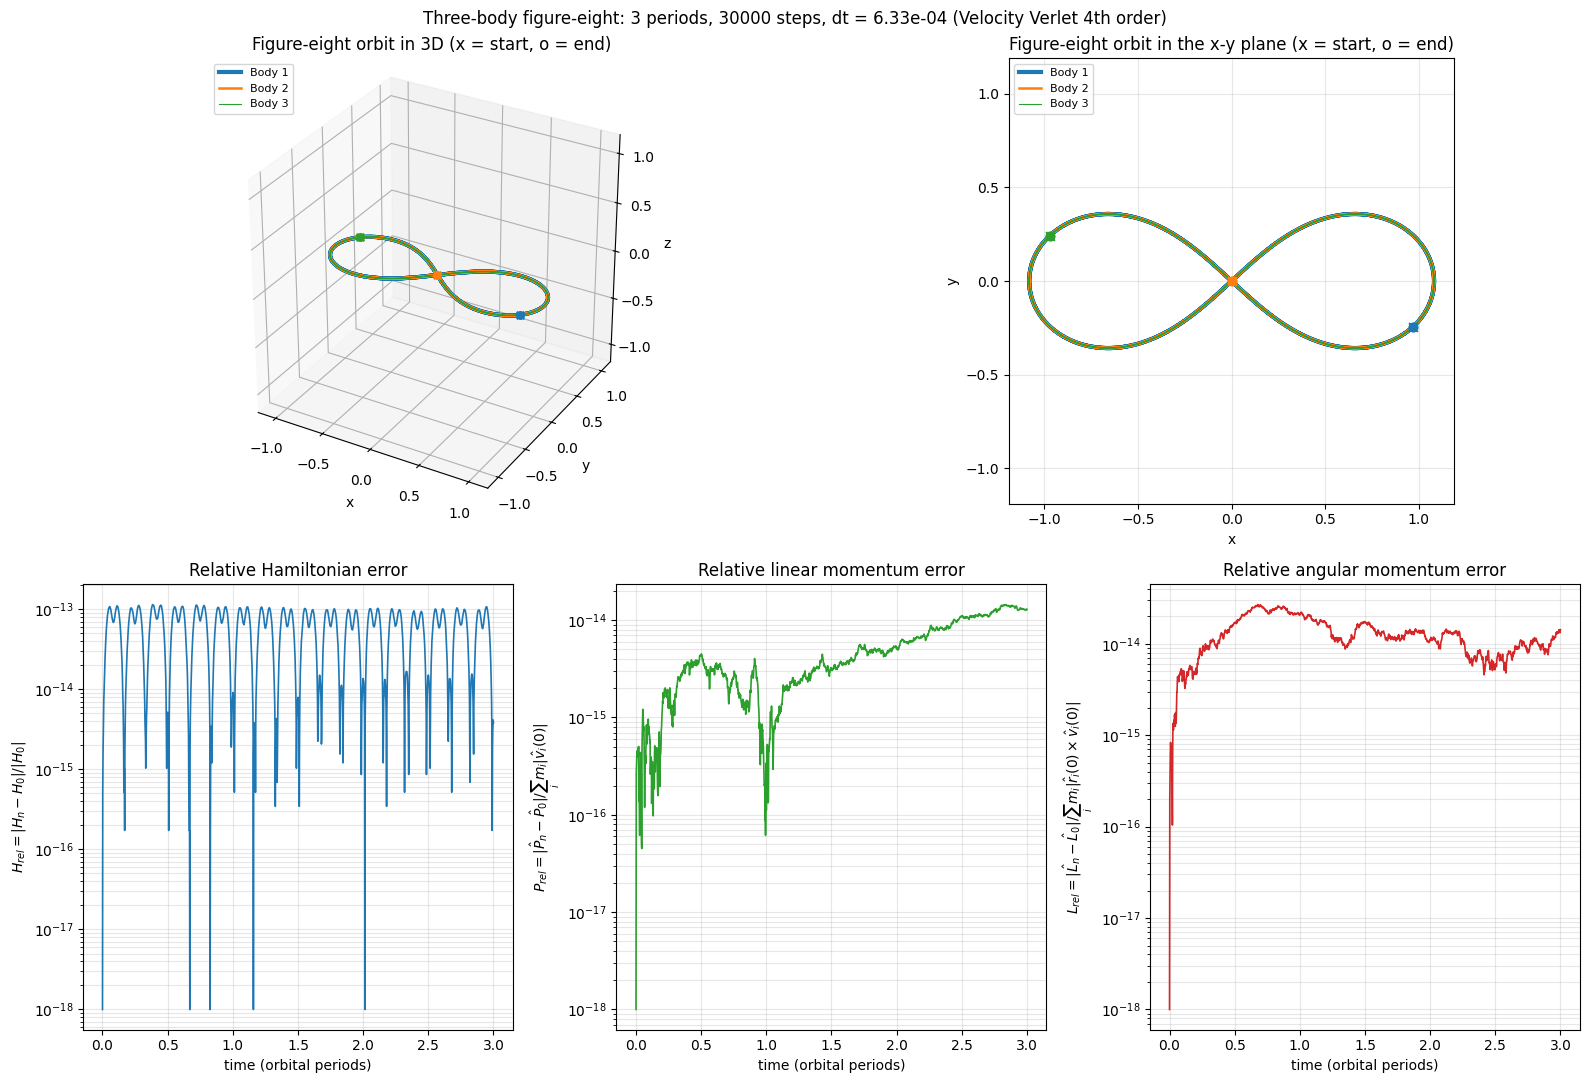

In [5]:
"""
Experiment 1: the three-body figure-eight choreography (28/10/26).

Purpose:
    The figure-eight is a periodic solution of the planar three-body problem in which
    three equal masses chase one another along a single closed curve shaped like the
    number eight. It was found numerically by Moore (1993) and its existence was proven
    by Chenciner & Montgomery (2000). Because the exact answer is known (the bodies must
    return to their starting positions after every period T), it is an ideal first
    validation test for the integrator: any drift away from the starting positions after
    a whole number of periods is a direct measure of the numerical error.

Setup:
    - three equal masses chasing each other along a single figure-eight curve
    - initial conditions from Simo's high-precision values, in natural units G = m = 1
    - no softening: the bodies never come close, and softening would perturb the orbit
    - integrated with run_vv_4 (Velocity Verlet 4th order)

Time control:
    - the total simulated time is a whole number of orbital periods
    - dt is dictated by the number of timesteps: dt = t_total / n_steps
    - frames are computed separately: one trajectory point is stored every
      steps_per_frame = n_steps / n_frames steps
Conservation tracking:
    The Hamiltonian H and the linear and angular momenta P and L are evaluated at every stored
    frame (conservation_state), and their relative errors H_rel, P_rel and L_rel are plotted
    together with the orbit in 3D and its 2D projection onto the x-y plane. The output is these five
    plots plus the closure error after the run.
"""


# A minimal body: mass, displacement, velocity and acceleration.
# The integrator (run_vv_4) and the force routine (acc) only ever access the
# attributes m, r, v and a, so any object that carries these four attributes
# can be simulated. All vectors are stored as 3-component NumPy arrays, so that
# the same code works for planar (z = 0) and fully three-dimensional problems.
class Body:
    def __init__(self, m, r, v):
        self.m = m      # mass (scalar)
        self.r = np.array(r, dtype=float)       # displacement vector (x, y, z)
        self.v = np.array(v, dtype=float)       # velocity vector (vx, vy, vz)
        self.a = np.zeros(3)        # acceleration vector, filled in by run_vv_4 on its first call


# Experiment parameters (natural units: G = 1, m = 1)
# The published figure-eight initial conditions are dimensionless: they assume G = 1
# and unit masses. Working in SI units would require rescaling every quantity, so the
# experiment is run directly in these natural units. Lengths, times and velocities
# printed below are therefore dimensionless as well.
G_nat = 1.0     # gravitational constant in natural units

# Plummer softening (Eq. 4) is switched off. The closest approach between any two
# bodies on the figure-eight is about 0.7 length units, so there is no risk of a
# division by zero, and any non-zero softening would alter the force law and hence
# destroy the periodicity that this experiment relies on.
e_soft = 0.0    # softening length (switched off, see above)

# Period of one full figure-eight orbit in natural units. After exactly one period
# every body returns to its own starting position. The value is only known to a
# finite number of digits, which sets a lower floor on the closure error below.
T_period = 6.32591398     # period of the figure-eight orbit (Simo's value, 9 significant digits)

# The three numbers below fully control the time discretisation:
#   n_periods – how long the simulation runs (t_total = n_periods * T_period)
#   n_steps – how finely that time is divided (this alone dictates dt)
#   n_frames – how many snapshots are stored for plotting (independent of dt)
# Increasing n_steps makes dt smaller and the result more accurate (the global error
# of the 4th-order scheme falls as dt^4) at a proportionally higher cost, while
# n_frames only changes the resolution of the plots and the memory used.
n_periods = 3   # number of full orbits to simulate
n_steps = 30000     # total number of timesteps (dictates dt)
n_frames = 1500     # number of stored trajectory points (independent of dt)

# Derived time quantities
t_total = n_periods * T_period      # total simulated time
dt = t_total / n_steps      # timestep implied by the chosen number of steps

# The integration is split into n_frames equal blocks of steps_per_frame steps each,
# and one snapshot is stored at the end of every block. For the blocks to add up to
# exactly n_steps, n_steps must be an integer multiple of n_frames; otherwise the run
# would stop short of (or overshoot) t_total and the closure test would be invalid.
assert n_steps % n_frames == 0, "n_steps must be divisible by n_frames"
steps_per_frame = n_steps // n_frames       # integration steps between two stored snapshots

# Initial conditions
# The configuration at t = 0 is symmetric:
#   – body 2 sits exactly at the crossing point (centre) of the eight
#   – bodies 1 and 3 sit at mirror-image positions, r3 = -r1
#   – bodies 1 and 3 share the same velocity, and body 2 moves with -2 times it
# These conditions give zero total momentum (m*v1 + m*v2 + m*v3 = 0), so the centre of
# mass stays fixed at the origin and no correction for drift is needed (unlike in a
# system with a randomly launched star). All z-components are zero, so the motion
# remains in the x-y plane for the entire run.
r1 = [0.97000436, -0.24308753, 0.0]     # displacement of body 1 (body 3 is its mirror image)
v2 = [-0.93240737, -0.86473146, 0.0]    # velocity of the central body 2
v13 = [-0.5 * v2[0], -0.5 * v2[1], 0.0]     # v1 = v3 = -v2 / 2, so the total momentum is zero

# The three bodies, each with unit mass
bodies = [
    Body(1.0, r1, v13),     # body 1: right-hand lobe
    Body(1.0, [0.0, 0.0, 0.0], v2),     # body 2: centre of the eight
    Body(1.0, [-r1[0], -r1[1], 0.0], v13),      # body 3: left-hand lobe
]

# Copies of the starting positions, kept for the closure test at the end of the run.
# .copy() is essential: without it r_start would refer to the same arrays that the
# integrator overwrites, and the closure error would always read zero.
r_start = [b.r.copy() for b in bodies]

# Summary of the time discretisation actually used
print(f"t_total = {t_total:.4f} ({n_periods} periods), n_steps = {n_steps}, dt = {dt:.3e}")
print(f"n_frames = {n_frames}, steps_per_frame = {steps_per_frame}")

# Conservation references
# The state at t = 0 is the reference for every relative error. P_0 and L_0 are exactly
# zero for this configuration (see the initial-conditions comment above), so p_rel and
# l_rel fall back on the characteristic size of the individual momenta, p_scale and l_scale.
H_0, P_0, L_0 = conservation_state(bodies, G_nat, e_soft)
P_scale, L_scale = p_scale(bodies), l_scale(bodies)
print(f"H_0 = {H_0:.6f}, |P_0| = {np.linalg.norm(P_0):.1e}, |L_0| = {np.linalg.norm(L_0):.1e}")

# Simulation
# trajectories[k] is the list of stored displacements of body k. It starts with the
# initial position, so after the loop each list holds n_frames + 1 points (t = 0 plus
# one point per block). run_vv_4 advances the bodies in place by steps_per_frame steps
# of size dt; after each call the new positions are copied into the record and the
# conserved quantities are measured on the freshly updated bodies.
# NB: run_vv_4 recomputes the accelerations at the start of every call. This costs one
# extra force evaluation per frame but does not change the result, because the
# accelerations depend only on the current positions.
trajectories = [[b.r.copy()] for b in bodies]
h_err, p_err, l_err = [0.0], [0.0], [0.0]       # relative errors at t = 0 are zero by definition
for _ in range(n_frames):
    run_vv_4(bodies, G_nat, e_soft, dt, steps_per_frame)
    for k, b in enumerate(bodies):
        trajectories[k].append(b.r.copy())

    H_n, P_n, L_n = conservation_state(bodies, G_nat, e_soft)
    h_err.append(h_rel(H_0, H_n))
    p_err.append(p_rel(P_0, P_n, P_scale))
    l_err.append(l_rel(L_0, L_n, L_scale))

# Convert the nested lists into a single array for convenient slicing:
#   axis 0 – body index k, axis 1 -> frame index, axis 2 -> coordinate (x, y, z)
trajectories = np.array(trajectories)       # shape: (N bodies, n_frames + 1, 3)
h_err, p_err, l_err = np.array(h_err), np.array(p_err), np.array(l_err)
t_frames = np.arange(n_frames + 1) * steps_per_frame * dt / T_period    # time in orbital periods

# Validation
# Closure check: after a whole number of periods every body should be back where it
# started. The distance |r(t_total) - r(0)| therefore measures the accumulated error.
# It contains two contributions: the integration error of the scheme (which shrinks as
# dt^4 when n_steps is increased) and the finite precision of T_period and of the
# initial conditions (which does not shrink with dt). Once the error stops decreasing
# when n_steps is raised, the second contribution has become dominant.
for k, b in enumerate(bodies):
    print(f"body {k + 1}: closure error |r(T) - r(0)| = {np.linalg.norm(b.r - r_start[k]):.3e}")

# Planarity check: with all z-components initially zero, the accelerations of Eq. (4)
# have no z-component either, so z must remain exactly zero for the whole run.
print(f"max |z| over the run = {np.abs(trajectories[:, :, 2]).max():.3e} (the orbit is planar)")

# Conservation summary
print(f"max H_rel = {h_err.max():.3e}, max P_rel = {p_err.max():.3e}, max L_rel = {l_err.max():.3e}")

# Plots: 3D orbit + 2D orbit + the three relative conservation errors
colours = plt.cm.tab10(np.arange(3))        # one distinct colour per body

# All three bodies travel along the very same curve, so lines of equal width would hide
# one another. Drawing them with decreasing widths (body 1 widest, body 3 thinnest)
# keeps every trajectory visible as a coloured band inside the previous one.
line_widths = [3.0, 1.8, 0.8]
fig = plt.figure(figsize=(16, 11))

# Layout on a 2 x 6 grid: the two orbit views share the top row (3 columns each) and the
# three conservation panels share the bottom row (2 columns each).
grid = fig.add_gridspec(2, 6)

# 3D view
# The orbit is planar, so this view shows the eight lying flat at z = 0. Any spurious
# out-of-plane motion would be visible here. The end markers (o) should lie on top of
# the start markers (x) because the run covers a whole number of periods.
ax3d = fig.add_subplot(grid[0, 0:3], projection="3d")
for k in range(len(bodies)):
    x, y, z = trajectories[k].T     # transpose (frames, 3) three coordinate arrays
    ax3d.plot(x, y, z, color=colours[k], lw=line_widths[k], label=f"Body {k + 1}")
    ax3d.scatter(x[0], y[0], z[0], color=colours[k], marker="x", s=30)     # starting position
    ax3d.scatter(x[-1], y[-1], z[-1], color=colours[k], s=30)       # final position

# Use the same limits on all three axes and a cubic box, so that lengths in different
# directions are directly comparable and the orbit is not visually distorted.
lim = 1.1 * np.abs(trajectories).max()      # 10% margin around the furthest point reached
ax3d.set_xlim(-lim, lim)
ax3d.set_ylim(-lim, lim)
ax3d.set_zlim(-lim, lim)
ax3d.set_box_aspect((1, 1, 1))
ax3d.set_xlabel("x")
ax3d.set_ylabel("y")
ax3d.set_zlabel("z")
ax3d.set_title("Figure-eight orbit in 3D (x = start, o = end)")
ax3d.legend(fontsize=8, loc="upper left")

# 2D view
# The motion is planar, so the projection onto the x-y plane shows the true shape of the
# orbit without the perspective distortion of the 3D view. An equal aspect ratio keeps the
# eight undistorted, so that its two lobes can be compared directly.
ax2d = fig.add_subplot(grid[0, 3:6])
for k in range(len(bodies)):
    x, y = trajectories[k, :, 0], trajectories[k, :, 1]
    ax2d.plot(x, y, color=colours[k], lw=line_widths[k], label=f"Body {k + 1}")
    ax2d.scatter(x[0], y[0], color=colours[k], marker="x", s=40, zorder=3)     # starting position
    ax2d.scatter(x[-1], y[-1], color=colours[k], s=40, zorder=3)       # final position
ax2d.set_xlim(-lim, lim)
ax2d.set_ylim(-lim, lim)
ax2d.set_aspect("equal")
ax2d.set_xlabel("x")
ax2d.set_ylabel("y")
ax2d.set_title("Figure-eight orbit in the x-y plane (x = start, o = end)")
ax2d.legend(fontsize=8, loc="upper left")
ax2d.grid(alpha=0.3)

# Relative conservation errors (logarithmic y-axis, time measured in orbital periods).
# The floor of 1e-18 only keeps exact zeros (e.g. at t = 0) drawable on a log axis.
floor = 1e-18
panels = [
    (h_err, r"$H_{rel}=|H_n-H_0|/|H_0|$", "Relative Hamiltonian error", "tab:blue"),
    (p_err, r"$P_{rel}=|\hat{P}_n-\hat{P}_0|/\sum_i m_i|\hat{v}_i(0)|$", "Relative linear momentum error", "tab:green"),
    (l_err, r"$L_{rel}=|\hat{L}_n-\hat{L}_0|/\sum_i m_i|\hat{r}_i(0)\times\hat{v}_i(0)|$", "Relative angular momentum error", "tab:red"),
]
for idx, (err, ylabel, title, colour) in enumerate(panels):
    ax = fig.add_subplot(grid[1, 2 * idx:2 * idx + 2])
    ax.semilogy(t_frames, np.maximum(err, floor), color=colour, lw=1.2)
    ax.set_xlabel("time (orbital periods)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, which="both")

fig.suptitle(f"Three-body figure-eight: {n_periods} periods, {n_steps} steps, "
             f"dt = {dt:.2e} (Velocity Verlet 4th order)")
plt.tight_layout()
plt.show()

## Creating the Barnes-Hut Octree
The direct summation of Eq. (4) evaluates every pair of bodies and therefore scales as $\mathcal{O}(N^2)$. The cell below implements the Barnes-Hut octree (Barnes & Hut, 1986), which approximates the same acceleration in $\mathcal{O}(N\log N)$ operations. The routine `acc_bh` is written as a drop-in replacement for `acc`, and `run_vv_4` accepts either of them through its `acc_func` argument, so that the integrator itself remains unchanged.


In [6]:
"""
Creating the Barnes-Hut Octree (30/10/26).
It consists of the tree construction, the mass moments of every node and the tree walk
that evaluates the approximate gravitational acceleration of every body.

acc_bh has exactly the same signature as the direct summation acc (plus the opening
angle theta), so it can be handed to run_vv_4 through its acc_func argument.
The detailed description of the algorithm will be provided later down below.
"""

# Maximum depth of the tree. Two bodies sitting at (almost) the same position can never be
# separated by subdividing the cube, so without this limit the insertion would recurse
# forever. At depth 32 a cube is 2^32 times smaller than the root, far below any physical
# separation in these simulations, so the limit only ever acts as a safety net.
max_depth_bh = 32


# A single node of the octree: one cubic cell of space.
# centre – geometric centre of the cube (3-vector)
# half – half of the side length of the cube (scalar)
# m – total mass of all bodies inside the cube (filled in by moments_bh)
# com – centre of mass of all bodies inside the cube (filled in by moments_bh)
# bodies – indices of the bodies stored in this node (only used while it is a leaf)
# children – list of 8 child nodes once the cube has been subdivided, None for a leaf
class Node:
    def __init__(self, centre, half):
        self.centre = np.array(centre, dtype=float)
        self.half = half
        self.m = 0.0
        self.com = np.zeros(3)
        self.bodies = []
        self.children = None


# Find the octant (0-7) of a node that contains the displacement r.
# Each bit of the index answers one question: bit 0 – is x on the positive side of the
# centre, bit 1 – is y, bit 2 – is z. Hence octant = [x >= c_x] + 2[y >= c_y] + 4[z >= c_z].
# node – the node being subdivided
# r – displacement vector of the body
def octant_bh(node, r):
    return int(r[0] >= node.centre[0]) + 2 * int(r[1] >= node.centre[1]) + 4 * int(r[2] >= node.centre[2])


# Split a leaf into 8 equal child cubes of half the side length.
# The child with index k is shifted from the parent centre by half/2 in every direction,
# with the sign of each shift taken from the corresponding bit of k (same rule as octant_bh).
# node – the leaf to be subdivided
def subdivide_bh(node):
    quarter = 0.5 * node.half       # half-width of every child
    node.children = []
    for k in range(8):
        sign = np.array([1.0 if k & 1 else -1.0,
                         1.0 if k & 2 else -1.0,
                         1.0 if k & 4 else -1.0])
        node.children.append(Node(node.centre + quarter * sign, quarter))


# Insert body i into the subtree that starts at node.
# A leaf may hold a single body. When a second body arrives the leaf is subdivided, the
# body already living there is pushed down into its octant, and the insertion continues
# into the octant of the new body. This repeats until every body sits alone in a leaf.
# node – current node of the descent
# i – index of the body in bod_obj
# bod_obj – a list of stellar bodies represented as objects
# depth – depth of node in the tree (the root has depth 0)
def insert_bh(node, i, bod_obj, depth):
    if node.children is None:
        # Empty leaf (or the depth limit is reached): simply store the body here
        if not node.bodies or depth >= max_depth_bh:
            node.bodies.append(i)
            return

        # Occupied leaf: subdivide and push the resident body one level down
        subdivide_bh(node)
        for j in node.bodies:
            insert_bh(node.children[octant_bh(node, bod_obj[j].r)], j, bod_obj, depth + 1)
        node.bodies = []

    # Internal node: descend into the octant that contains body i
    insert_bh(node.children[octant_bh(node, bod_obj[i].r)], i, bod_obj, depth + 1)


# Compute the total mass and the centre of mass of every node (post-order traversal).
# Leaf: M = sum of the masses of its bodies, R = their mass-weighted mean position.
# Internal node: the same sums taken over the 8 children, M = sum_k M_k, R = sum_k M_k R_k / M.
# node – root of the subtree
# bod_obj – a list of stellar bodies represented as objects
def moments_bh(node, bod_obj):
    if node.children is None:
        for j in node.bodies:
            node.m += bod_obj[j].m
            node.com += bod_obj[j].m * bod_obj[j].r
    else:
        for child in node.children:
            moments_bh(child, bod_obj)
            node.m += child.m
            node.com += child.m * child.com

    if node.m > 0.0:
        node.com /= node.m      # numerator above is sum m r, divide by the mass to obtain R


# Build the complete octree for the current positions of all bodies.
# The root is the smallest cube that encloses every body, enlarged by a tiny margin so that
# no body lies exactly on its outer boundary.
# bod_obj – a list of stellar bodies represented as objects
def build_tree_bh(bod_obj):
    positions = np.array([obj.r for obj in bod_obj])
    lower, upper = positions.min(axis=0), positions.max(axis=0)
    centre = 0.5 * (lower + upper)
    half = 0.5 * np.max(upper - lower) * (1.0 + 1e-6) + 1e-12    # +1e-12 guards a single body

    root = Node(centre, half)
    for i in range(len(bod_obj)):
        insert_bh(root, i, bod_obj, 0)
    moments_bh(root, bod_obj)

    return root


# Check whether the displacement r lies inside the cube of a node
def contains_bh(node, r):
    return np.all(np.abs(r - node.centre) <= node.half)


# Acceleration of body i due to all the mass inside the subtree that starts at node.
# Opening criterion: a node of side s = 2*half seen from distance d = |r_i - R| is accepted
# as a single point mass at its centre of mass if s / d < theta, otherwise it is opened and
# its children are visited. A node that contains body i itself is always opened (see the
# explanation below). Leaves are summed exactly, which is Eq. (4) restricted to the leaf.
# node – current node of the tree walk
# i – index of the body that feels the force
# bod_obj – a list of stellar bodies represented as objects
# G – the constant of gravitational attraction
# e – softening factor (same Plummer softening as in acc)
# theta – opening angle
def node_acc_bh(node, i, bod_obj, G, e, theta):
    a_i = np.zeros(3)
    if node.m == 0.0:
        return a_i      # empty cube: no contribution

    r_i = bod_obj[i].r

    # Leaf: exact summation over the bodies stored in it (skipping self-interaction)
    if node.children is None:
        for j in node.bodies:
            if j == i:
                continue
            r_ij = r_i - bod_obj[j].r
            denominator = (np.dot(r_ij, r_ij) + e**2)**1.5
            a_i += -G * bod_obj[j].m * r_ij / denominator
        return a_i

    # Internal node: accept it as one pseudo-body or open it
    r_iN = r_i - node.com       # displacement from the centre of mass of the node to body i
    dist = np.sqrt(np.dot(r_iN, r_iN))
    s = 2.0 * node.half         # side length of the cube

    # s / d < theta is written without a division, and the (more expensive) containment test is
    # only evaluated for nodes that already pass the opening criterion
    if s < theta * dist and not contains_bh(node, r_i):
        denominator = (dist**2 + e**2)**1.5
        return -G * node.m * r_iN / denominator

    for child in node.children:
        a_i += node_acc_bh(child, i, bod_obj, G, e, theta)

    return a_i


# Compute Gravitational Acceleration of All Bodies with the Barnes-Hut approximation.
# A drop-in replacement for acc: same arguments and same output (a list of 3-vectors).
# G – the constant of gravitational attraction
# bod_obj – a list of stellar bodies represented as objects
# e – softening factor
# theta – opening angle; theta = 0 opens every node and reproduces direct summation,
#         larger values are faster but less accurate (0.5 - 1.0 is the usual range)
def acc_bh(G, bod_obj, e, theta=0.5):
    root = build_tree_bh(bod_obj)       # the tree is rebuilt at every force evaluation, since the bodies move
    return [node_acc_bh(root, i, bod_obj, G, e, theta) for i in range(len(bod_obj))]


## Barnes-Hut Octree Explanation
The cost of a gravitational N-body simulation is dominated by the force evaluation. Eq. (4) sums the contribution of every body $j\neq i$ to the acceleration of body $i$, which requires $N(N-1)$ pair evaluations per call, and the 4th-order Velocity Verlet calls it three times per timestep. For the large $N$ of cosmological applications this quadratic cost is prohibitive.

The Barnes-Hut algorithm (Barnes & Hut, 1986) rests on a simple physical observation: a compact group of bodies that is far away from body $i$ pulls on it almost exactly like a single body carrying the total mass of the group and located at its centre of mass. The algorithm organises the bodies into a hierarchy of cubic cells, an *octree*, and decides for every cell whether it is distant enough to be replaced by such a pseudo-body or whether it has to be examined in more detail.

**Notation.** In addition to the notation of the Velocity Verlet explanation, $c$ denotes a cell (a node of the tree), $\hat{c}$ its geometric centre, $s$ its side length (`2 * half` in the code), $M_c$ the total mass it contains and $\hat{R}_c$ its centre of mass. $d$ is the distance from body $i$ to $\hat{R}_c$ and $\theta$ is the opening angle.

### Spatial Decomposition (Octree Construction)
The root cell is the smallest cube that encloses all bodies (`build_tree_bh`). Every cell can be split into eight equal octants of half the side length (`subdivide_bh`). The octant of a cell that contains a displacement $\hat{r}=(x,y,z)$ is identified by three binary comparisons with the centre $\hat{c}=(c_x,c_y,c_z)$ (`octant_bh`, Eq. (18)):

$$k=[x\geq c_x]+2\,[y\geq c_y]+4\,[z\geq c_z],\qquad k\in\{0,\dots,7\} \tag{18}$$

where $[\,\cdot\,]$ equals 1 if the condition holds and 0 otherwise. The centre of child $k$ is displaced from the parent centre by a quarter of the parent side length along each axis (Eq. (19)),

$$\hat{c}_k=\hat{c}+\frac{s}{4}\,(\sigma_x,\sigma_y,\sigma_z),\qquad \sigma\in\{-1,+1\} \tag{19}$$

with each sign $\sigma$ taken from the corresponding bit of $k$.

The bodies are inserted one by one (`insert_bh`). A body descends from the root into the octant that contains it until it reaches an empty leaf, where it is stored. When it reaches a leaf that is already occupied, that leaf is subdivided and both bodies are pushed further down, until each of them occupies a leaf of its own. For a roughly uniform distribution the depth of the tree grows as $\log_8 N$, so the construction costs $\mathcal{O}(N\log N)$. Two bodies at (almost) identical positions cannot be separated by any number of subdivisions, so a maximum depth (`max_depth_bh`) is imposed, beyond which a leaf may hold more than one body.

### Mass Moments of the Cells
Every cell is described by its total mass and its centre of mass (`moments_bh`, Eq. (20)):

$$M_c=\sum_{j\in c}m_j,\qquad \hat{R}_c=\frac{1}{M_c}\sum_{j\in c}m_j\,\hat{r}_j \tag{20}$$

These are computed from the bottom of the tree upwards: a leaf sums over its bodies directly, while an internal cell combines the moments of its eight children, $M_c=\sum_k M_k$ and $\hat{R}_c=\sum_k M_k\hat{R}_k/M_c$. Every body therefore contributes to one cell per level, and the whole pass costs $\mathcal{O}(N\log N)$.

### Opening Criterion and Tree Walk
The acceleration of body $i$ is obtained by walking the tree from the root (`node_acc_bh`). For each cell the ratio of its size to its distance from body $i$ is compared with the opening angle,

$$\frac{s}{d}<\theta,\qquad d=\lvert\hat{r}_i-\hat{R}_c\rvert \tag{21}$$

If the criterion of Eq. (21) holds, the cell subtends a small angle as seen from body $i$ and its entire content is replaced by a single softened point mass at $\hat{R}_c$ (Eq. (22)):

$$\hat{a}_i^{(c)}=-G\,\frac{M_c\,(\hat{r}_i-\hat{R}_c)}{\left(\lvert\hat{r}_i-\hat{R}_c\rvert^2+\epsilon^2\right)^{3/2}} \tag{22}$$

which has exactly the form of a single term of Eq. (4). If the criterion fails, the cell is *opened* and the same test is applied to each of its children. When a leaf is reached, its bodies are summed exactly as in Eq. (4). The total acceleration is the sum of all accepted contributions (`acc_bh`).

A cell that contains body $i$ itself is always opened, regardless of the criterion. Without this rule a large cell whose centre of mass happens to lie far from body $i$ could pass the test although body $i$ sits inside it, which produces large force errors (Salmon & Warren, 1994). The rule also guarantees that body $i$ never interacts with itself, since it can only be met inside its own leaf, where the term $j=i$ is skipped.

The opening angle controls the trade-off between accuracy and cost:
- $\theta=0$: no cell is ever accepted, every cell is opened down to its leaves, and the algorithm reproduces direct summation exactly (up to the order of floating-point additions). This limit is used in Experiment 2 to validate the implementation.
- $\theta\approx0.5$–$1$: the range commonly used in practice.
- larger $\theta$: faster, but increasingly inaccurate.

### Accuracy and Cost
Because the expansion is taken about the centre of mass, the dipole term of the multipole expansion of a cell vanishes identically. The leading error of the point-mass approximation is therefore the quadrupole term (Salmon & Warren, 1994), and the relative error of a single accepted cell scales as

$$\frac{\lvert\delta\hat{a}_i^{(c)}\rvert}{\lvert\hat{a}_i^{(c)}\rvert}\sim\mathcal{O}\!\left(\left(\frac{s}{d}\right)^2\right)\lesssim\mathcal{O}(\theta^2) \tag{23}$$

so, by Eq. (23), halving $\theta$ reduces the force error roughly fourfold. The number of cells accepted by a single body grows only logarithmically with $N$ (approximately as $\theta^{-3}\log N$), hence one complete force evaluation costs $\mathcal{O}(N\log N)$ instead of $\mathcal{O}(N^2)$ (Barnes & Hut, 1986). The tree has to be rebuilt at every force evaluation, since the bodies move, but this is also an $\mathcal{O}(N\log N)$ operation.

In this pure-Python prototype the bookkeeping of the tree outweighs the saving for the small $N$ that can be simulated, so `acc_bh` is not yet faster than `acc`. The asymptotic advantage becomes decisive only for large $N$ in the compiled C++ implementation.

### Consequences for the Conserved Quantities
The approximation does not only introduce a small force error; it also breaks the symmetries on which the conservation laws of the previous section rely.

**Linear momentum.** In direct summation the force of $j$ on $i$ is exactly opposite to the force of $i$ on $j$ (Newton's third law), so the internal forces cancel in pairs and $\hat{P}$ (Eq. (14)) is conserved. In the tree, body $i$ may see body $j$ as part of a distant cell, while body $j$ sees body $i$ individually or as part of a different cell. The two forces are then no longer equal and opposite, and $\hat{P}$ drifts (Springel, 2005).

**Angular momentum.** For the same reason, and because an accepted cell pulls towards $\hat{R}_c$ rather than along the individual lines joining the bodies, the internal torques no longer cancel and $\hat{L}$ (Eq. (16)) is not exactly conserved either.

**Energy.** Velocity Verlet and its Yoshida composition are symplectic for forces that derive from a potential (Hairer, Lubich & Wanner, 2006), $\hat{a}_i=-\frac{1}{m_i}\nabla_{\hat{r}_i}V$. The tree force is not the gradient of the exact potential $V$ of the Hamiltonian, nor of any single smooth potential, since the tree is rebuilt at every evaluation and the force changes discontinuously whenever a cell switches between being accepted and being opened. The bounded energy oscillation that characterises a symplectic integrator is therefore no longer guaranteed, and $H_{rel}$ (Eq. (13)), which is always evaluated with the exact $V$ (Eq. (11)), is expected to be larger and to grow with $\theta$.

Measuring how strongly these three properties degrade for a given $\theta$ is precisely the purpose of Experiment 2.

### One Force Evaluation in the Code
1. Find the bounding cube of all bodies and insert them one by one into the octree (`build_tree_bh`, `insert_bh`, `subdivide_bh`, `octant_bh`).
2. Compute $M_c$ and $\hat{R}_c$ for every cell from the leaves upwards (`moments_bh`).
3. For every body $i$, walk the tree from the root, accepting cells that satisfy $s/d<\theta$ and do not contain body $i$, and opening all others (`node_acc_bh`, `contains_bh`).
4. Return the list of accelerations in the same format as `acc` (`acc_bh`), so that `run_vv_4(..., acc_func=...)` can use it without modification.


N = 64, t_total = 5.6569 (2 crossing times), n_steps = 500, dt = 1.131e-02, softening = 0.05
H_0 = -0.27363 (-0.25 for an infinite Plummer sphere; the difference is sampling noise of finite N), virial ratio 2T/|V| = 1.000

Force accuracy at t = 0 (relative error per body):
  theta = 0.0: mean = 2.24e-16, max = 5.35e-16
  theta = 0.5: mean = 4.64e-03, max = 1.88e-02
  theta = 1.0: mean = 3.90e-02, max = 1.26e-01

Running simulations (this takes a few minutes in pure Python)...
  Direct summation         runtime =   20.4 s, max H_rel = 2.52e-05, max P_rel = 3.71e-16, max L_rel = 2.66e-15
  Barnes-Hut theta = 0.5   runtime =   24.7 s, max H_rel = 2.23e-03, max P_rel = 2.00e-03, max L_rel = 4.26e-03
  Barnes-Hut theta = 1.0   runtime =   17.6 s, max H_rel = 1.26e-02, max P_rel = 1.12e-02, max L_rel = 2.89e-02
  mean final separation from the direct run (Barnes-Hut theta = 0.5) = 3.18e-01 a
  mean final separation from the direct run (Barnes-Hut theta = 1.0) = 7.71e-01 a


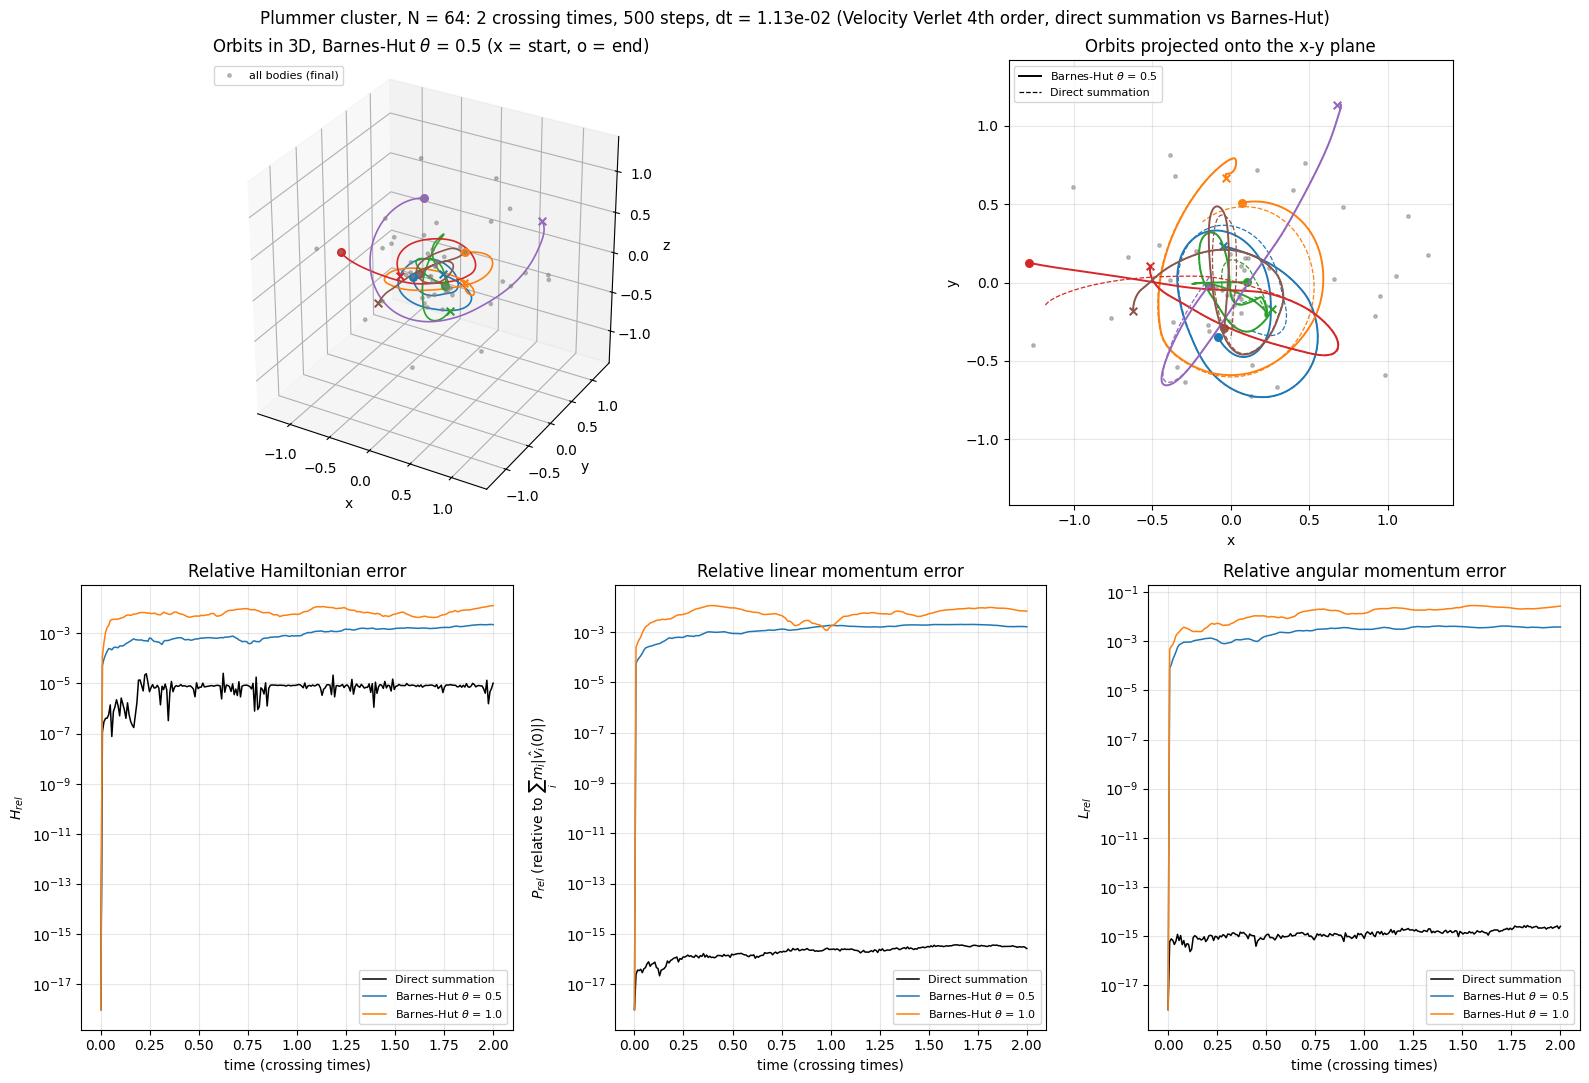

In [7]:
"""
Experiment 2: Barnes-Hut octree against direct summation in a Plummer star cluster (30/10/26).

Purpose:
    Experiment 1 validated the Velocity Verlet 4th order integrator on a problem with a
    known exact answer. This experiment keeps the integrator fixed and changes only the
    force routine, in order to isolate the effect of the Barnes-Hut approximation on the
    reliability of the simulation. The same initial conditions are integrated with the
    same timestep three times:
        - direct summation, acc (the reference, exact up to rounding)
        - Barnes-Hut, acc_bh with theta = 0.5 (the usual accuracy setting)
        - Barnes-Hut, acc_bh with theta = 1.0 (a deliberately coarse setting)
    Any difference between the runs is therefore caused by the force approximation alone.

Setup:
    - N equal-mass bodies drawn from a Plummer sphere (Plummer 1911), the standard
      self-gravitating test model of N-body dynamics, sampled with the method of
      Aarseth, Henon & Wielen (1974)
    - Henon units: G = 1, total mass M = 1, total energy E = -1/4, which fixes the
      Plummer scale length to a = 3*pi/16
    - the cluster is moved to its centre-of-mass frame and its velocities are rescaled to
      exact virial equilibrium (2T = -V), so it should neither collapse nor expand
    - Plummer softening is switched ON: the bodies are randomly placed, so close encounters
      do happen, and the softening keeps the force finite (Eq. 4)
    - the system is fully three-dimensional, so all eight octants of the tree are used

Time control:
    Identical to Experiment 1: t_total is a whole number of crossing times, dt = t_total / n_steps,
    and one snapshot is stored every steps_per_frame = n_steps / n_frames steps.

Conservation tracking:
    H, P and L are evaluated at every stored frame with the EXACT expressions of the
    conservation cell (direct pair sums), never with the tree. The Barnes-Hut runs are thus
    judged against the true Hamiltonian, which is the quantity that matters physically.

Expected outcome:
    - direct summation: P and L conserved to rounding error, H_rel small and bounded
    - Barnes-Hut: P and L no longer exact (tree forces violate Newton's third law), and
      H_rel larger, growing with theta (tree forces are not the gradient of the exact V)
    - individual trajectories of the three runs agree at first and then separate, because
      the N-body problem is chaotic and amplifies any small force difference exponentially
"""


# Plummer sphere sampler (Aarseth, Henon & Wielen 1974)
# Draws N bodies of mass M / N whose positions follow the Plummer density profile
#   rho(r) = 3 M / (4 pi a^3) * (1 + r^2 / a^2)^(-5/2)
# and whose speeds follow the matching isotropic distribution function.
# N – number of bodies
# G – the constant of gravitational attraction
# M – total mass of the cluster
# a – Plummer scale length
# r_cut – radius cut-off in units of a (removes the very rare, extremely distant bodies)
def init_plummer(N, G, M, a, r_cut=10.0):
    bod_obj = []

    # Random unit vector, uniformly distributed over the surface of a sphere
    def random_direction():
        cos_t = 2.0 * rnd.random() - 1.0        # cos(polar angle) uniform in [-1, 1]
        phi = 2.0 * np.pi * rnd.random()        # azimuth uniform in [0, 2 pi)
        sin_t = np.sqrt(1.0 - cos_t**2)
        return np.array([sin_t * np.cos(phi), sin_t * np.sin(phi), cos_t])

    for _ in range(N):
        # Radius: invert the cumulative mass profile M(r) / M = X  ->  r = a / sqrt(X^(-2/3) - 1)
        while True:
            X = rnd.random()
            if X > 0.0:
                r = a / np.sqrt(X**(-2.0 / 3.0) - 1.0)
                if r < r_cut * a:
                    break

        # Speed: v = q * v_esc, with q drawn from g(q) = q^2 (1 - q^2)^(7/2) by rejection.
        # The maximum of g on [0, 1] is about 0.092, so a box of height 0.1 encloses it.
        while True:
            q, y = rnd.random(), 0.1 * rnd.random()
            if y < q**2 * (1.0 - q**2)**3.5:
                break
        v_esc = np.sqrt(2.0 * G * M / np.sqrt(r**2 + a**2))     # local escape speed of the Plummer potential

        bod_obj.append(Body(M / N, r * random_direction(), q * v_esc * random_direction()))

    # Move to the centre-of-mass frame: subtract the mass-weighted mean position and velocity,
    # so that the cluster does not drift and P_0 = 0 (up to rounding)
    r_cm = sum(obj.m * obj.r for obj in bod_obj) / M
    v_cm = sum(obj.m * obj.v for obj in bod_obj) / M
    for obj in bod_obj:
        obj.r = obj.r - r_cm
        obj.v = obj.v - v_cm

    return bod_obj


# Rescale all velocities so that the cluster is in exact virial equilibrium, 2T + V = 0.
# Random sampling of N bodies only satisfies this on average; the rescaling removes the
# sampling noise so that the experiment starts from a genuinely equilibrated cluster.
def virialise(bod_obj, G, e):
    t, v = t_abs(bod_obj), v_abs(bod_obj, G, e)
    factor = np.sqrt(-0.5 * v / t)      # T scales with the square of the velocities
    for obj in bod_obj:
        obj.v = obj.v * factor


# Independent copy of a list of bodies, so that every run starts from identical conditions.
# Body() wraps r and v in np.array, which copies them.
def copy_bodies(bod_obj):
    return [Body(obj.m, obj.r, obj.v) for obj in bod_obj]


# Integrate one copy of the initial conditions and record trajectories and conservation errors.
# The loop is the same as in Experiment 1, wrapped in a function so that it can be repeated
# for every force routine. Only the time spent inside run_vv_4 is measured as the runtime.
# bod_init – initial conditions (left untouched)
# acc_func – force routine handed to run_vv_4
def simulate(bod_init, G, e, dt, n_frames, steps_per_frame, acc_func):
    bod_obj = copy_bodies(bod_init)

    H_0, P_0, L_0 = conservation_state(bod_obj, G, e)
    P_sc, L_sc = p_scale(bod_obj), l_scale(bod_obj)

    trajectories = [[obj.r.copy()] for obj in bod_obj]
    h_err, p_err, l_err = [0.0], [0.0], [0.0]
    runtime = 0.0

    for _ in range(n_frames):
        clock = time.perf_counter()
        run_vv_4(bod_obj, G, e, dt, steps_per_frame, acc_func)
        runtime += time.perf_counter() - clock

        for k, obj in enumerate(bod_obj):
            trajectories[k].append(obj.r.copy())

        H_n, P_n, L_n = conservation_state(bod_obj, G, e)
        h_err.append(h_rel(H_0, H_n))
        p_err.append(p_rel(P_0, P_n, P_sc))
        l_err.append(l_rel(L_0, L_n, L_sc))

    return {"traj": np.array(trajectories), "h": np.array(h_err), "p": np.array(p_err),
            "l": np.array(l_err), "time": runtime}


# Experiment parameters (Henon units: G = 1, M = 1, E = -1/4)
G_nat = 1.0     # gravitational constant
M_tot = 1.0     # total mass of the cluster
a_pl = 3.0 * np.pi / 16.0       # Plummer scale length giving E = -1/4 in Henon units
N_bodies = 64       # number of bodies (kept small: the prototype is pure Python)

# Softening: a few per cent of the scale length. It must be large enough to tame close
# encounters at the chosen dt, and small compared with the mean separation of the bodies
# (about 0.4 length units here) so that the cluster still behaves like point masses.
e_soft_2 = 0.05

# The crossing time t_cr = 2 sqrt(2) is the time a typical body needs to cross the cluster
# in Henon units. Two crossing times are long enough for the bodies to complete roughly
# one orbit and for the runs to separate, while keeping the pure-Python runtime modest.
t_cross = 2.0 * np.sqrt(2.0)
n_crossings = 2     # simulated time in crossing times
n_steps_2 = 500     # total number of timesteps (dictates dt)
n_frames_2 = 250    # number of stored snapshots (independent of dt)

t_total_2 = n_crossings * t_cross
dt_2 = t_total_2 / n_steps_2
assert n_steps_2 % n_frames_2 == 0, "n_steps_2 must be divisible by n_frames_2"
steps_per_frame_2 = n_steps_2 // n_frames_2

# Force routines under test. acc_bh takes the opening angle as an extra argument, so a
# lambda fixes theta and leaves the (G, bod_obj, e) signature that run_vv_4 expects.
theta_values = [0.5, 1.0]
force_routines = {"Direct summation": acc}
for th in theta_values:
    force_routines[f"Barnes-Hut theta = {th}"] = (lambda G, b, e, th=th: acc_bh(G, b, e, th))
    # th=th binds the current value; a plain lambda would see only the last theta of the loop

# Initial conditions (re-seeded here, so the cluster is the same regardless of which cells ran before)
rnd.seed(seed)
cluster = init_plummer(N_bodies, G_nat, M_tot, a_pl)
virialise(cluster, G_nat, e_soft_2)

print(f"N = {N_bodies}, t_total = {t_total_2:.4f} ({n_crossings} crossing times), "
      f"n_steps = {n_steps_2}, dt = {dt_2:.3e}, softening = {e_soft_2}")
H_init = h_abs(t_abs(cluster), v_abs(cluster, G_nat, e_soft_2))
print(f"H_0 = {H_init:.5f} (-0.25 for an infinite Plummer sphere; the difference is sampling noise of finite N), "
      f"virial ratio 2T/|V| = {2 * t_abs(cluster) / abs(v_abs(cluster, G_nat, e_soft_2)):.3f}")

# Force accuracy at t = 0
# Before integrating, the tree accelerations are compared body by body with direct summation:
# delta_i = |a_i(BH) - a_i(direct)| / |a_i(direct)|. theta = 0 must reproduce direct summation
# to rounding error, which validates the tree construction and the walk.
a_direct = acc(G_nat, cluster, e_soft_2)
print("\nForce accuracy at t = 0 (relative error per body):")
for th in [0.0] + theta_values:
    a_tree = acc_bh(G_nat, cluster, e_soft_2, th)
    delta = np.array([np.linalg.norm(at - ad) / np.linalg.norm(ad) for at, ad in zip(a_tree, a_direct)])
    print(f"  theta = {th:.1f}: mean = {delta.mean():.2e}, max = {delta.max():.2e}")

# Simulations (the same initial conditions, three force routines)
print("\nRunning simulations (this takes a few minutes in pure Python)...")
results = {}
for label, func in force_routines.items():
    results[label] = simulate(cluster, G_nat, e_soft_2, dt_2, n_frames_2, steps_per_frame_2, func)
    res = results[label]
    print(f"  {label:<24} runtime = {res['time']:6.1f} s, "
          f"max H_rel = {res['h'].max():.2e}, max P_rel = {res['p'].max():.2e}, max L_rel = {res['l'].max():.2e}")

t_frames_2 = np.arange(n_frames_2 + 1) * steps_per_frame_2 * dt_2 / t_cross     # time in crossing times

# Divergence from the reference: mean distance between the same body in a tree run and in the
# direct run at the end of the simulation, in units of the Plummer scale length.
ref_label = "Direct summation"
for label, res in results.items():
    if label != ref_label:
        sep = np.linalg.norm(res["traj"][:, -1] - results[ref_label]["traj"][:, -1], axis=1).mean()
        print(f"  mean final separation from the direct run ({label}) = {sep / a_pl:.2e} a")

# Plots: 3D and 2D trajectories + the three relative conservation errors
# The trajectories shown are those of the theta = 0.5 run. With 64 bodies a full plot would be
# unreadable, so a handful of bodies that stay inside the cluster (r < 2.5 a for the whole run)
# are drawn in colour, while the final positions of all bodies are shown as grey dots.
show_label = f"Barnes-Hut theta = {theta_values[0]}"
traj_show = results[show_label]["traj"]
traj_ref = results[ref_label]["traj"]

n_show = 6
bound = [k for k in range(N_bodies) if np.linalg.norm(traj_show[k], axis=1).max() < 2.5 * a_pl]
highlight = rnd.sample(bound, min(n_show, len(bound)))
colours_2 = plt.cm.tab10(np.arange(len(highlight)))
lim_2 = 1.1 * np.abs(traj_show[highlight]).max()

fig = plt.figure(figsize=(16, 11))
grid = fig.add_gridspec(2, 6)

# 3D view of the highlighted orbits
ax3d = fig.add_subplot(grid[0, 0:3], projection="3d")
final = traj_show[:, -1]
inside = np.all(np.abs(final) < lim_2, axis=1)      # 3D axes do not clip, so far-away bodies are left out
ax3d.scatter(*final[inside].T, color="grey", s=6, alpha=0.5, label="all bodies (final)")
for c, k in enumerate(highlight):
    x, y, z = traj_show[k].T
    ax3d.plot(x, y, z, color=colours_2[c], lw=1.2)
    ax3d.scatter(x[0], y[0], z[0], color=colours_2[c], marker="x", s=30)
    ax3d.scatter(x[-1], y[-1], z[-1], color=colours_2[c], s=30)
ax3d.set_xlim(-lim_2, lim_2)
ax3d.set_ylim(-lim_2, lim_2)
ax3d.set_zlim(-lim_2, lim_2)
ax3d.set_box_aspect((1, 1, 1))
ax3d.set_xlabel("x")
ax3d.set_ylabel("y")
ax3d.set_zlabel("z")
ax3d.set_title(rf"Orbits in 3D, Barnes-Hut $\theta$ = {theta_values[0]} (x = start, o = end)")
ax3d.legend(fontsize=8, loc="upper left")

# 2D projection onto the x-y plane, with the direct-summation orbit of the same body dashed.
# The two curves start on top of each other and separate as the chaotic dynamics amplify the
# small force differences: this is the visual counterpart of the final-separation printout.
ax2d = fig.add_subplot(grid[0, 3:6])
ax2d.scatter(final[:, 0], final[:, 1], color="grey", s=6, alpha=0.5)
for c, k in enumerate(highlight):
    ax2d.plot(traj_show[k, :, 0], traj_show[k, :, 1], color=colours_2[c], lw=1.4)
    ax2d.plot(traj_ref[k, :, 0], traj_ref[k, :, 1], color=colours_2[c], lw=0.9, ls="--")
    ax2d.scatter(traj_show[k, 0, 0], traj_show[k, 0, 1], color=colours_2[c], marker="x", s=30)
    ax2d.scatter(traj_show[k, -1, 0], traj_show[k, -1, 1], color=colours_2[c], s=30)
ax2d.plot([], [], color="black", lw=1.4, label=rf"Barnes-Hut $\theta$ = {theta_values[0]}")
ax2d.plot([], [], color="black", lw=0.9, ls="--", label="Direct summation")
ax2d.set_xlim(-lim_2, lim_2)
ax2d.set_ylim(-lim_2, lim_2)
ax2d.set_aspect("equal")
ax2d.set_xlabel("x")
ax2d.set_ylabel("y")
ax2d.set_title("Orbits projected onto the x-y plane")
ax2d.legend(fontsize=8, loc="upper left")
ax2d.grid(alpha=0.3)

# Relative conservation errors of all three runs on common axes
floor = 1e-18
run_colours = {ref_label: "black"}
for th, colour in zip(theta_values, ["tab:blue", "tab:orange"]):
    run_colours[f"Barnes-Hut theta = {th}"] = colour

panels_2 = [
    ("h", r"$H_{rel}$", "Relative Hamiltonian error"),
    ("p", r"$P_{rel}$ (relative to $\sum_i m_i|\hat{v}_i(0)|$)", "Relative linear momentum error"),
    ("l", r"$L_{rel}$", "Relative angular momentum error"),
]
for idx, (key, ylabel, title) in enumerate(panels_2):
    ax = fig.add_subplot(grid[1, 2 * idx:2 * idx + 2])
    for label, res in results.items():
        ax.semilogy(t_frames_2, np.maximum(res[key], floor), color=run_colours[label], lw=1.1,
                    label=label.replace("theta", r"$\theta$"))     # LaTeX theta in the legend
    ax.set_xlabel("time (crossing times)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=8)

fig.suptitle(f"Plummer cluster, N = {N_bodies}: {n_crossings} crossing times, {n_steps_2} steps, "
             f"dt = {dt_2:.2e} (Velocity Verlet 4th order, direct summation vs Barnes-Hut)")
plt.tight_layout()
plt.show()


# Creating Leapfrog Integrator

## About Leapfrog

Leapfrog is a numerical integrator quite similar to the Velocity Verlet second-order integrator, since they are numerically cousins. The method is called that way due to its internal mathematical structure of kick-drift-kick, where the integration leaps like a frog. For our implementation we apply the second-order methodology. We also apply previous helper equations from Eq. 1 through Eq. 4.

Due to the nature of the algorithm, it computes its steps differently to the Verlet integrator:
- Compute initial ("kick") half-step velocity applying $a_0$ as acceleration value
- Compute displacement ("drift")
- Compute new acceleration
- Compute final "kick"

In [ ]:
"""
Leapfrog Second-Order Implementation.
Consists of the displacement, velocity and runtime computations.

Detailed algorithmic solution will be provided later down below in the description.
"""

# Compute initial kick by half a timestep
# obj – individual object with accessible properties
# t – current timestep
# Theoretically, the initial half-velocity will be assigned to the object and retrieved later
def veli_l_2(obj, t):
    return obj.v + obj.a * (0.5 * t)

# Compute Displacement applying first kick
# obj – individual object with accessible properties
# t – current timestep
def displ_l_2(obj, t):
    return obj.r + obj.v * t

# Compute final kick by the second half-step
# obj – individual object with accessible properties
# t – current timestep
def velf_l_2(obj, t):
    return obj.v + obj.a * (0.5 * t)

# Run Leapfrog
# bod_obj – a list of stellar bodies represented as objects.
#           Contains objects themselves. Allows to access
#           individual parameters such as: mass, initial velocity,
#           and initial displacement.
# G – the constant of gravitational attraction
# e – softening factor to prevent division by 0 errors in case
#     the bodies get too close.
# dt – timestep of the simulation
# n_steps – number of timesteps to take
# acc_func – force routine used for every acceleration evaluation. Defaults to the direct
#            summation acc; any function with the same (G, bod_obj, e) arguments and output
#            can be passed instead, such as the Barnes-Hut acc_bh (see Experiment 2).
# NB: the initial conditions (r, v, m) must be set on every body before calling this.
def run_l_2(bod_obj, G, e, dt, n_steps, acc_func=acc):

    # Find initial accelerations of all bodies
    for obj, a in zip(bod_obj, acc_func(G, bod_obj, e)):
        obj.a = a

    # Start the clock of the simulated Universe
    for _ in range(n_steps):

        # Kick: half-step velocity of ALL bodies with the old acceleration a_n
        for obj in bod_obj:
            obj.v = veli_l_2(obj, dt)

        # Drift: move ALL bodies by a full step with the half-step velocity
        for obj in bod_obj:
            obj.r = displ_l_2(obj, dt)

        # Re-evaluate the forces once for the whole system (new acceleration a_{n+1})
        for obj, a in zip(bod_obj, acc_func(G, bod_obj, e)):
            obj.a = a

        # Kick: complete the velocity update with the new acceleration a_{n+1}
        for obj in bod_obj:
            obj.v = velf_l_2(obj, dt)


## References
- Aarseth, S. J., Hénon, M. and Wielen, R. (1974) A comparison of numerical methods for the study of star cluster dynamics. *Astronomy and Astrophysics*, 37, 183–187.
- Barnes, J. and Hut, P. (1986) A hierarchical $\mathcal{O}(N\log N)$ force-calculation algorithm. *Nature*, 324, 446–449.
- Chenciner, A. and Montgomery, R. (2000) A remarkable periodic solution of the three-body problem in the case of equal masses. *Annals of Mathematics*, 152(3), 881–901.
- Dehnen, W. and Read, J. I. (2011) N-body simulations of gravitational dynamics. *The European Physical Journal Plus*, 126, 55.
- Forest, E. and Ruth, R. D. (1990) Fourth-order symplectic integration. *Physica D: Nonlinear Phenomena*, 43(1), 105–117.
- Hairer, E., Lubich, C. and Wanner, G. (2006) *Geometric Numerical Integration: Structure-Preserving Algorithms for Ordinary Differential Equations*. 2nd edn. Berlin: Springer.
- Moore, C. (1993) Braids in classical dynamics. *Physical Review Letters*, 70(24), 3675–3679.
- Plummer, H. C. (1911) On the problem of distribution in globular star clusters. *Monthly Notices of the Royal Astronomical Society*, 71, 460–470.
- Salmon, J. K. and Warren, M. S. (1994) Skeletons from the treecode closet. *Journal of Computational Physics*, 111(1), 136–155.
- Simó, C. (2002) Dynamical properties of the figure eight solution of the three-body problem. In: Chenciner, A., Cushman, R., Robinson, C. and Xia, Z. J. (eds) *Celestial Mechanics: Dedicated to Donald Saari for his 60th Birthday*. Contemporary Mathematics, 292. Providence: American Mathematical Society, 209–228.
- Springel, V. (2005) The cosmological simulation code GADGET-2. *Monthly Notices of the Royal Astronomical Society*, 364(4), 1105–1134.
- Swope, W. C., Andersen, H. C., Berens, P. H. and Wilcox, K. R. (1982) A computer simulation method for the calculation of equilibrium constants for the formation of physical clusters of molecules: application to small water clusters. *The Journal of Chemical Physics*, 76(1), 637–649.
- Verlet, L. (1967) Computer "experiments" on classical fluids. I. Thermodynamical properties of Lennard-Jones molecules. *Physical Review*, 159(1), 98–103.
- Yoshida, H. (1990) Construction of higher order symplectic integrators. *Physics Letters A*, 150(5–7), 262–268.
